# 02 · Discount payback

**Question:** at what discount depth does extra volume stop making up for the lower price, so that revenue or margin per article falls?

**Method** (PROJECT_PLAN 4.2–4.3; code in `src/fdda/features/pricing.py` and `src/fdda/analysis/discount.py`):
1. Reference (full) price per article-week = 95th percentile of the article's price over a trailing 8-week window (lifetime max if the window is too thin). Discount = 1 − price ÷ reference, grouped into bands.
2. **Band indexes:** for each article, units / indexed revenue / margin per week in a discount band ÷ the same at full price, then the median across articles.
   * *Local baseline* (headline): full-price weeks of the same article within ±8 weeks. Markdowns come late in an article's life, when demand has already faded; comparing with launch weeks would blame the discount for that decline.
   * *Lifetime baseline:* all full-price weeks (the plan as written), shown as a sensitivity check.
3. **Margins** assume 50%, 60% or 70% gross margin at full price (there is no cost data).
4. **Elasticity:** log(units) on log(1 − discount) with article, week and article-age fixed effects.
5. **Ceiling:** the last band before each extra discount point starts to *lower* the margin index.

This notebook reads the tables written by `python -m fdda.analysis.discount`; it does not recompute them.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from fdda import viz
from fdda.config import data_mode, load_settings, resolve_path

settings = load_settings()
MODE = data_mode(settings)
D = resolve_path(settings, "reports") / "discount"
FIGURES = resolve_path(settings, "figures")
LABELS = settings["pricing"]["discount_bands"]["labels"]
MARGINS = settings["pricing"]["margin_scenarios"]
CENTRAL = settings["pricing"]["central_margin"]
HEADLINE = settings["discount_analysis"]["headline_baseline"]
CM = f"margin_index_{round(CENTRAL * 100)}"

econ = pd.read_csv(D / f"band_economics_{MODE}.csv")
th = pd.read_csv(D / f"thresholds_{MODE}.csv")
el = pd.read_csv(D / f"elasticity_{MODE}.csv")
my = pd.read_csv(D / f"myntra_crosscheck_{MODE}.csv")
summary = json.loads((D / f"discount_summary_{MODE}.json").read_text())
viz.apply_style()
pd.options.display.float_format = "{:,.3f}".format
SCOPE = "all customers" if MODE == "full" else "10% customer sample"
print(f"Data mode: {MODE} ({SCOPE}); headline baseline: {HEADLINE}")
pd.Series(summary["article_weeks"]).to_frame("value")

Data mode: full (all customers); headline baseline: local


,value
transactions,"31,788,324.000"
units_in_article_weeks,"31,788,324.000"
dropped_no_reference_price,0.000
article_weeks,"2,210,899.000"
articles,"104,547.000"
share_article_weeks_lifetime_fallback,0.127
seconds,93.800


## 1. Do discounted weeks sell more?

Median units per week in each band relative to the same article at full price.

,n_articles,band_discount,units_index,units_index_p25,units_index_p75,revenue_index,margin_index_50,margin_index_60,margin_index_70
band,,,,,,,,,
0-5%,91145,0.000,1.000,0.978,1.006,1.000,1.000,1.000,1.000
5-15%,67378,0.100,0.849,0.545,1.206,0.783,0.716,0.740,0.756
15-25%,61469,0.200,1.059,0.667,1.714,0.916,0.742,0.802,0.844
25-35%,37495,0.295,1.000,0.504,1.593,0.700,0.413,0.510,0.578
35-45%,35698,0.400,1.100,0.658,2.042,0.771,0.270,0.445,0.566
45-55%,35245,0.500,1.094,0.625,2.300,0.681,0.011,0.246,0.409
55%+,31644,0.606,1.000,0.614,2.182,0.500,-0.257,-0.000,0.161


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


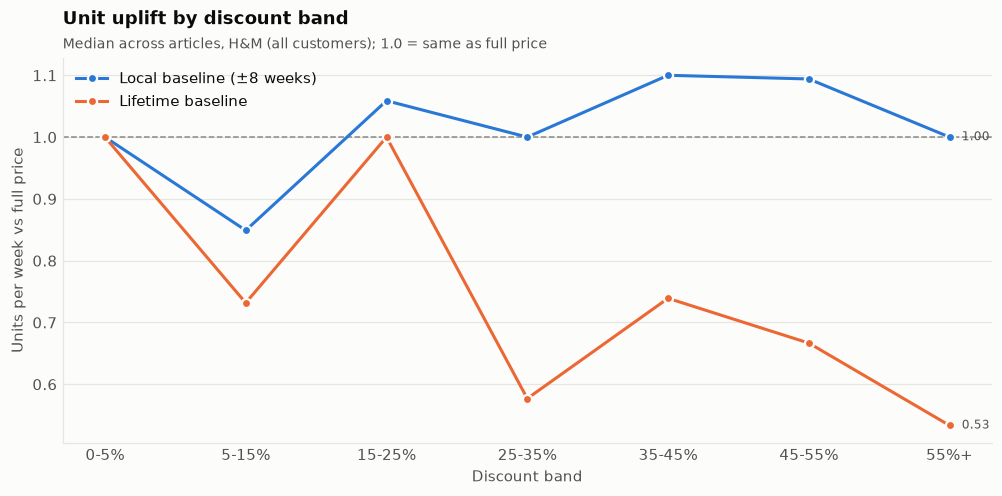

In [2]:
def band_view(baseline, category="All"):
    v = econ[(econ.baseline == baseline) & (econ.category == category)].set_index("band")
    return v.reindex(LABELS)


local, life = band_view("local"), band_view("lifetime")
display(
    local[
        [
            "n_articles",
            "band_discount",
            "units_index",
            "units_index_p25",
            "units_index_p75",
            "revenue_index",
            *[f"margin_index_{round(m * 100)}" for m in MARGINS],
        ]
    ]
)

fig, ax = viz.new_fig(9, 4.4)
viz.index_lines(
    ax,
    LABELS,
    {"Local baseline (±8 weeks)": local["units_index"], "Lifetime baseline": life["units_index"]},
)
ax.set_xlabel("Discount band")
ax.set_ylabel("Units per week vs full price")
ax.set_title("Unit uplift by discount band", pad=22)
viz.subtitle(ax, f"Median across articles, H&M ({SCOPE}); 1.0 = same as full price")
viz.save_fig(fig, f"payback_units_uplift_{MODE}", FIGURES)
plt.show()

## 2. Revenue and margin by discount band

The payback question: do the extra units make up for the lower price? Each line is a median index across articles (1.0 = the same revenue or margin per week as at full price). Two readings: does any discount beat full price, and, once an article is marked down, beyond which depth do deeper markdowns stop paying back? The dotted line marks the second (central margin scenario).

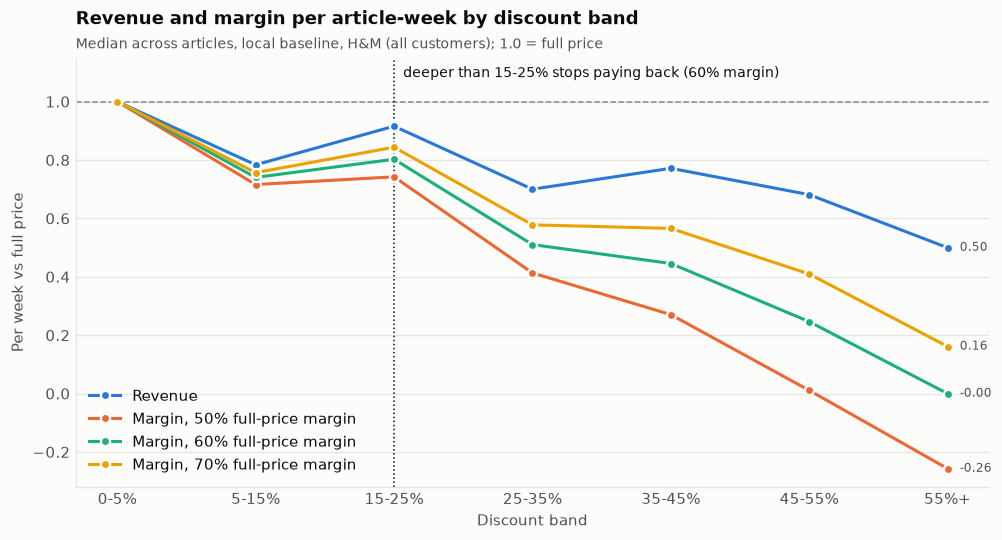

,measure,reference,ceiling_band,ceiling_discount,ceiling_index,turns_negative,first_negative_band
0,units_index,full price,0-5%,0.000,1.000,True,5-15%
10,units_index,from 5-15%,15-25%,0.200,1.059,True,25-35%
20,revenue_index,full price,0-5%,0.000,1.000,True,5-15%
30,revenue_index,from 5-15%,15-25%,0.200,0.916,True,25-35%
40,margin_index_50,full price,0-5%,0.000,1.000,True,5-15%
50,margin_index_50,from 5-15%,15-25%,0.200,0.742,True,25-35%
60,margin_index_60,full price,0-5%,0.000,1.000,True,5-15%
70,margin_index_60,from 5-15%,15-25%,0.200,0.802,True,25-35%
80,margin_index_70,full price,0-5%,0.000,1.000,True,5-15%
90,margin_index_70,from 5-15%,15-25%,0.200,0.844,True,25-35%


In [3]:
head = band_view(HEADLINE)
series = {"Revenue": head["revenue_index"]}
for m in MARGINS:
    series[f"Margin, {m:.0%} full-price margin"] = head[f"margin_index_{round(m * 100)}"]
ceiling = summary["among_discounts"]["overall"]

fig, ax = viz.new_fig(9, 4.8)
viz.index_lines(ax, LABELS, series)
k = LABELS.index(ceiling["ceiling_band"])
ax.axvline(k, color=viz.TEXT, linewidth=1, linestyle=":")
ax.annotate(
    f"deeper than {ceiling['ceiling_band']} stops paying back ({CENTRAL:.0%} margin)",
    (k, 1.0),
    xytext=(6, 16),
    textcoords="offset points",
    fontsize=9,
    color=viz.TEXT,
)
ax.set_ylim(top=max(ax.get_ylim()[1], 1.15))
ax.set_xlabel("Discount band")
ax.set_ylabel("Per week vs full price")
ax.legend(loc="lower left")
ax.set_title("Revenue and margin per article-week by discount band", pad=22)
viz.subtitle(ax, f"Median across articles, {HEADLINE} baseline, H&M ({SCOPE}); 1.0 = full price")
viz.save_fig(fig, f"payback_threshold_{MODE}", FIGURES)
plt.show()

cols = [
    "measure",
    "reference",
    "ceiling_band",
    "ceiling_discount",
    "ceiling_index",
    "turns_negative",
    "first_negative_band",
]
display(th[(th.category == "All") & (th.baseline == HEADLINE)][cols])

## 3. Ceiling by category

Margin index (central scenario) per category and band; outlined cells are each category's ceiling *among discount levels*. Blue = more margin per week than at full price, red = less.

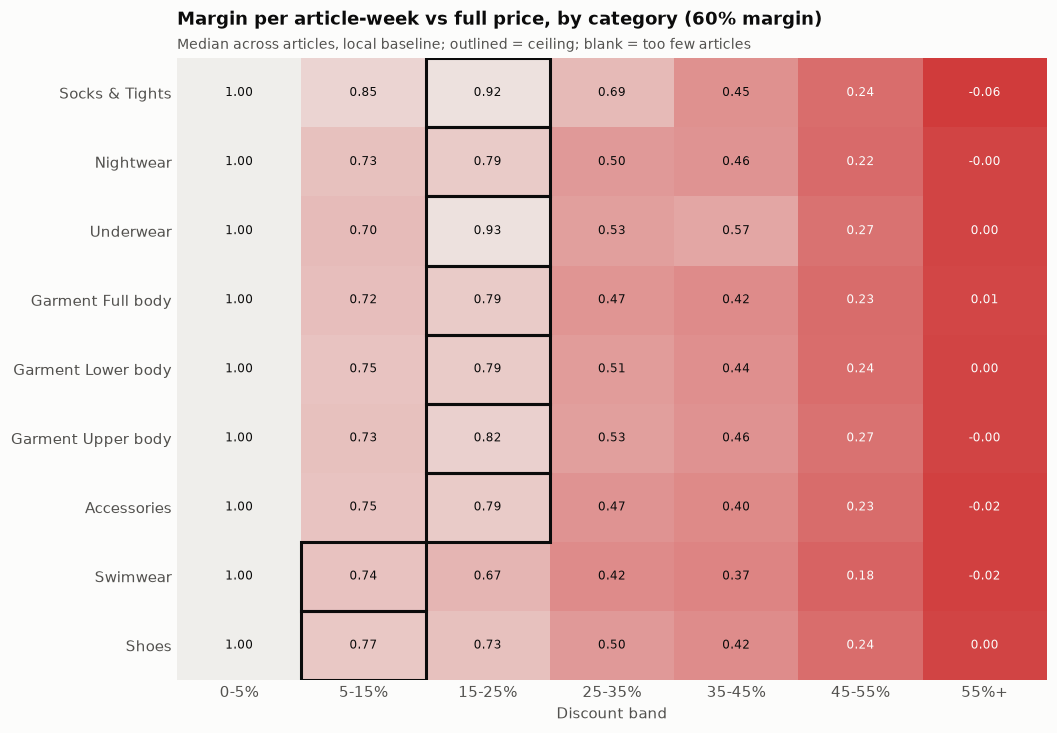

reference               from 5-15%                                  \
measure            margin_index_50 margin_index_60 margin_index_70   
category                                                             
Accessories                 15-25%          15-25%          15-25%   
All                         15-25%          15-25%          15-25%   
Garment Full body           15-25%          15-25%          15-25%   
Garment Lower body          15-25%          15-25%          15-25%   
Garment Upper body          15-25%          15-25%          15-25%   
Nightwear                   15-25%          15-25%          15-25%   
Shoes                        5-15%           5-15%           5-15%   
Socks & Tights              15-25%          15-25%          15-25%   
Swimwear                     5-15%           5-15%           5-15%   
Underwear                   15-25%          15-25%          15-25%   

reference               full price                                  
measure            margin_index_50 margin_index_60 margin_index_70  
category                                                            
Accessories                   0-5%            0-5%            0-5%  
All                           0-5%            0-5%            0-5%  
Garment Full body             0-5%            0-5%            0-5%  
Garment Lower body            0-5%            0-5%            0-5%  
Garment Upper body            0-5%            0-5%            0-5%  
Nightwear                     0-5%            0-5%            0-5%  
Shoes                         0-5%            0-5%            0-5%  
Socks & Tights                0-5%            0-5%            0-5%  
Swimwear                      0-5%            0-5%            0-5%  
Underwear                     0-5%            0-5%            0-5%

In [4]:
cat = econ[(econ.baseline == HEADLINE) & (econ.category != "All")]
grid = cat.pivot(index="category", columns="band", values=CM).reindex(columns=LABELS)
cth = th[
    (th.baseline == HEADLINE)
    & (th.measure == CM)
    & (th.reference != "full price")
    & (th.category != "All")
].set_index("category")
grid = grid.loc[
    [c for c in cth.sort_values("ceiling_discount", ascending=False).index if c in grid.index]
]
marks = [(r, LABELS.index(cth.loc[c, "ceiling_band"])) for r, c in enumerate(grid.index)]

fig, ax = viz.new_fig(9.5, 0.55 * len(grid) + 1.6)
viz.diverging_heatmap(ax, grid.to_numpy(dtype=float), list(grid.index), LABELS, marks=marks)
ax.set_xlabel("Discount band")
ax.set_title(f"Margin per article-week vs full price, by category ({CENTRAL:.0%} margin)", pad=22)
viz.subtitle(
    ax, f"Median across articles, {HEADLINE} baseline; outlined = ceiling; blank = too few articles"
)
viz.save_fig(fig, f"payback_category_heatmap_{MODE}", FIGURES)
plt.show()

ceil_tbl = th[(th.baseline == HEADLINE) & th.measure.str.startswith("margin_index")]
display(
    ceil_tbl.pivot_table(
        index="category", columns=["reference", "measure"], values="ceiling_band", aggfunc="first"
    )
)

## 4. Price elasticity

Fixed-effects estimate of how units respond to the price ratio (β ≈ % change in units for a 1% change in price ÷ reference price; negative = discounts lift volume). The article-age control removes lifecycle decay; without it, late-life markdowns make discounts look ineffective. The implied margin-optimal discount under a constant elasticity is shown for each margin scenario.

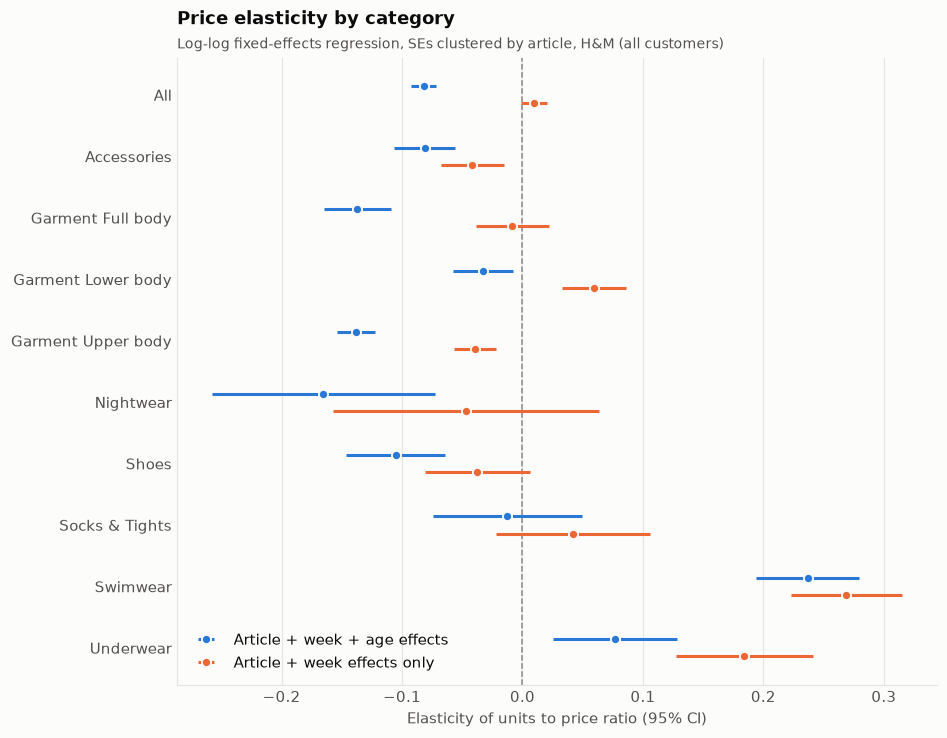

,beta,se,ci_low,ci_high,n_obs,n_articles,share_obs_discounted,implied_optimal_discount_50,implied_optimal_discount_60,implied_optimal_discount_70
category,,,,,,,,,,
All,-0.082,0.005,-0.092,-0.072,2205365,99013,0.495,0.000,0.000,0.000
Accessories,-0.081,0.013,-0.107,-0.056,206450,10304,0.464,0.000,0.000,0.000
Garment Full body,-0.137,0.014,-0.165,-0.109,266524,12554,0.520,0.000,0.000,0.000
Garment Lower body,-0.033,0.013,-0.058,-0.008,442377,18663,0.486,0.000,0.000,0.000
Garment Upper body,-0.138,0.008,-0.154,-0.122,880634,40028,0.503,0.000,0.000,0.000
Nightwear,-0.165,0.047,-0.258,-0.073,27809,1774,0.464,0.000,0.000,0.000
Shoes,-0.105,0.021,-0.146,-0.064,91333,4950,0.488,0.000,0.000,0.000
Socks & Tights,-0.012,0.031,-0.074,0.049,49238,2248,0.577,0.000,0.000,0.000
Swimwear,0.237,0.022,0.194,0.280,93051,3030,0.495,0.000,0.000,0.000


In [5]:
spec_age, spec_plain = "article+week+age FE", "article+week FE"
e1 = el[el.spec == spec_age].set_index("category")
e0 = el[el.spec == spec_plain].set_index("category").reindex(e1.index)

fig, ax = viz.new_fig(8.5, 0.5 * len(e1) + 1.6)
viz.forest(
    ax,
    list(e1.index),
    {
        "Article + week + age effects": (e1.beta, e1.ci_low, e1.ci_high),
        "Article + week effects only": (e0.beta, e0.ci_low, e0.ci_high),
    },
)
ax.set_xlabel("Elasticity of units to price ratio (95% CI)")
ax.set_title("Price elasticity by category", pad=22)
viz.subtitle(ax, f"Log-log fixed-effects regression, SEs clustered by article, H&M ({SCOPE})")
viz.save_fig(fig, f"payback_elasticity_{MODE}", FIGURES)
plt.show()

display(
    e1[
        [
            "beta",
            "se",
            "ci_low",
            "ci_high",
            "n_obs",
            "n_articles",
            "share_obs_discounted",
            *[f"implied_optimal_discount_{round(m * 100)}" for m in MARGINS],
        ]
    ]
)

## 5. Myntra cross-check (directional)

Myntra has no sales, only a listing snapshot. Rating count proxies cumulative demand and price × rating count proxies revenue. Both are indexed to the 0–5% band. This is a cross-sectional association across *different* products (not the same product at different prices) and only a quarter of listings have any rating, so it is a sanity check on direction, not an estimate.

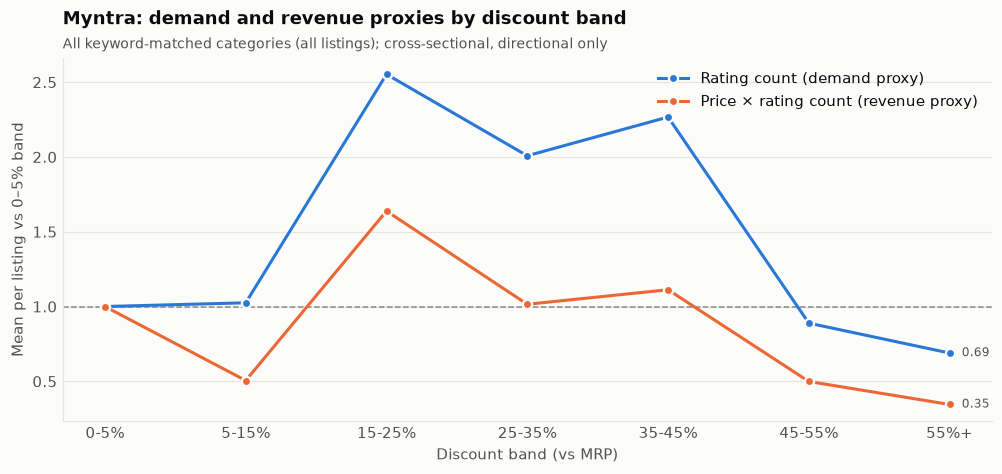

,listings,band_discount,share_rated,mean_ratings_index,mean_revenue_proxy_index
band,,,,,
0-5%,201523,0.000,0.202,1.000,1.000
5-15%,58019,0.100,0.225,1.025,0.505
15-25%,66410,0.200,0.261,2.553,1.638
25-35%,80693,0.300,0.247,2.008,1.015
35-45%,100901,0.400,0.265,2.267,1.112
45-55%,147123,0.500,0.295,0.889,0.499
55%+,405544,0.670,0.269,0.689,0.345


band,0-5%,5-15%,15-25%,25-35%,35-45%,45-55%,55%+
category,,,,,,,
All,1.000,0.505,1.638,1.015,1.112,0.499,0.345
Bags & accessories,1.000,0.216,0.432,0.655,0.847,1.202,0.629
Beauty & personal care,1.000,0.499,2.123,1.506,1.042,0.270,0.262
Bottoms,1.000,0.394,0.671,0.863,1.971,2.339,1.245
Dresses & jumpsuits,1.000,0.638,0.328,0.677,0.824,1.465,1.435
Ethnic wear,1.000,0.622,0.322,0.344,0.756,1.030,1.171
Footwear,1.000,1.510,1.495,1.828,1.812,1.879,1.545
Home,1.000,0.154,0.361,0.161,0.314,0.278,0.364
Innerwear & nightwear,1.000,0.634,0.904,1.632,0.567,0.390,0.432


In [6]:
ma = my[my.category == "All"].set_index("band").reindex(LABELS)
fig, ax = viz.new_fig(9, 4.2)
viz.index_lines(
    ax,
    LABELS,
    {
        "Rating count (demand proxy)": ma["mean_ratings_index"],
        "Price × rating count (revenue proxy)": ma["mean_revenue_proxy_index"],
    },
)
ax.set_xlabel("Discount band (vs MRP)")
ax.set_ylabel("Mean per listing vs 0–5% band")
ax.set_title("Myntra: demand and revenue proxies by discount band", pad=22)
viz.subtitle(
    ax,
    f"All keyword-matched categories ({SCOPE.replace('customer', 'listing')}); cross-sectional, directional only",
)
viz.save_fig(fig, f"payback_myntra_crosscheck_{MODE}", FIGURES)
plt.show()

display(
    ma[
        [
            "listings",
            "band_discount",
            "share_rated",
            "mean_ratings_index",
            "mean_revenue_proxy_index",
        ]
    ]
)
display(
    my.pivot(index="category", columns="band", values="mean_revenue_proxy_index").reindex(
        columns=LABELS
    )
)

## 6. Result

Headline numbers, read from `discount_summary_<mode>.json`:

In [7]:
vf, ad, el_all = summary["vs_full_price"], summary["among_discounts"], summary["elasticity_all"]
sens = summary["sensitivity_other_baseline"]
result = pd.Series(
    {
        f"Best band vs full price ({CENTRAL:.0%} margin)": f"{vf['overall']['ceiling_band']}",
        f"Markdown ceiling among discount levels ({CENTRAL:.0%} margin)": f"{ad['overall']['ceiling_band']} (median discount {ad['overall']['ceiling_discount']:.0%}, margin index {ad['overall']['ceiling_index']:.2f})",
        "Markdown ceiling range across 50–70% margins": f"{ad['range']['min']:.0%} to {ad['range']['max']:.0%}",
        "Revenue ceiling among discount levels": f"{ad['revenue']['ceiling_band']}",
        f"Margin ceiling with {sens.get('baseline', '-')} baseline (sensitivity)": f"{sens.get('ceiling_band', '-')}",
        "Elasticity, all articles (article+week+age FE)": f"{el_all['beta']:.2f} [{el_all['ci_low']:.2f}, {el_all['ci_high']:.2f}]",
        "Myntra band with highest revenue proxy": summary["myntra_peak_revenue_band"],
    },
    name="value",
)
result.to_frame()

,value
Best band vs full price (60% margin),0-5%
Markdown ceiling among discount levels (60% margin),"15-25% (median discount 20%, margin index 0.80)"
Markdown ceiling range across 50–70% margins,20% to 20%
Revenue ceiling among discount levels,15-25%
Margin ceiling with lifetime baseline (sensitivity),15-25%
"Elasticity, all articles (article+week+age FE)","-0.08 [-0.09, -0.07]"
Myntra band with highest revenue proxy,15-25%


**Caveats.** Markdowns are not randomised: slow sellers get discounted, and discount timing follows the season and the article's lifecycle. Article, week and age effects and the local baseline remove the main confounders, but these remain associations. Weeks with zero sales are not observed, H&M prices are normalised (revenue is indexed), and margins are assumptions. A randomised markdown test (A/B by store or customer cohort) is the way to confirm the ceiling; see `reports/pricing_recommendation.md`.